# Preprocessing

Demo of the `hotb_2026.preprocessing` package on the same synthetic signal as
`notebooks/brainaccess_connection/02_simulation.ipynb`.

Every completed window goes through:

1. notch filter at **50 Hz**,
2. band-pass **0.5–45 Hz**,
3. resample **250 → 200 Hz**,
4. **z-score** per channel, then **clip ±15**.

The package does not reimplement the driver, the streamer or the montage. It
reuses `SimulatedDriver`, `EEGStreamer` and `MONTAGE` from
`brainaccess_connection`, and plugs into the streamer with the normal
`add_processor()` API.

## Imports

Everything from `brainaccess_connection` is the existing API. Only the
preprocessing classes are new.

In [10]:
%matplotlib inline

import time
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import welch

from hotb_2026.brainaccess_connection import MONTAGE, EEGStreamer, SimulatedDriver
from hotb_2026.preprocessing import (
    PreprocessingConfig,
    Preprocessor,
    WindowedPreprocessor,
)

plt.rcParams["figure.dpi"] = 110
print("input rate:", MONTAGE.sfreq, "Hz; channels:", MONTAGE.names)

input rate: 250.0 Hz; channels: ['F3', 'F4', 'C3', 'C4', 'P3', 'P4', 'O1', 'O2']


## Source data

`SimulatedDriver` produces the same 10 Hz alpha plus noise as `02_simulation`.
We run it through a real `EEGStreamer` with a **10 s window** and attach two
existing-style processors:

* `capture_raw` stores the first full window,
* `WindowedPreprocessor` preprocesses **exactly that whole window** and appends
  the result to `processed`.

The preprocessing adapter is given `window_s=streamer.window_s` on purpose: the
streamer's window is the single source of truth, so there is no second, hidden
sub-window length. The run takes about 20 seconds (two windows) because the
simulated driver is paced in real time.

In [21]:
WINDOW_S = 10.0

driver = SimulatedDriver(MONTAGE, chunk_ms=40.0, seed=0)
streamer = EEGStreamer(
    driver,
    MONTAGE,
    stream_name="Preprocessing demo",
    source_id="preprocessing-demo-1",
    window_s=WINDOW_S,
)

config = PreprocessingConfig(sfreq=MONTAGE.sfreq)
preprocessor = Preprocessor(config)

raw_windows: deque[np.ndarray] = deque(maxlen=1)
processed: deque[tuple[np.ndarray, float]] = deque(maxlen=10)


def capture_raw(window, t):
    if streamer.is_full and not raw_windows:
        raw_windows.append(window.copy())


windowed = WindowedPreprocessor(
    preprocessor,
    sfreq=MONTAGE.sfreq,
    window_s=streamer.window_s,  # preprocess the whole established window
    on_window=lambda clean, t: processed.append((clean, t)),
)
streamer.add_processor(capture_raw)
streamer.add_processor(windowed)

streamer.start()
try:
    deadline = time.monotonic() + 30.0
    while streamer.running and len(processed) < 2 and time.monotonic() < deadline:
        time.sleep(0.2)
finally:
    streamer.stop()

raw = raw_windows[0]
print(f"streamer window: {streamer.window_s:g} s = {windowed.window_samples} samples")
print(f"raw window: {raw.shape} = {raw.shape[1] / MONTAGE.sfreq:g} s at {MONTAGE.sfreq:g} Hz")
print(f"live preprocessed windows: {len(processed)}")
if processed:
    print(f"  first window: {processed[0][0].shape} at {preprocessor.output_sfreq:g} Hz")
print("streamer.error:", streamer.error)


streamer window: 10 s = 2500 samples
raw window: (8, 2500) = 10 s at 250 Hz
live preprocessed windows: 2
  first window: (8, 2000) at 200 Hz
streamer.error: None


In [22]:
processed

deque([(array([[ 0.2622585 ,  0.5843204 ,  0.93427974, ..., -1.911192  ,
                -1.2928576 , -0.23258762],
               [ 0.1577253 ,  0.38597998,  0.89388084, ..., -0.88921136,
                -0.6126742 , -0.23464468],
               [ 0.15427133,  0.38004363,  0.7259278 , ..., -0.8931909 ,
                -0.55387396, -0.200995  ],
               ...,
               [ 0.00568034,  0.4534992 ,  0.8538238 , ..., -0.6973414 ,
                -0.48379147, -0.15571803],
               [ 0.14481494, -0.04769524,  0.2157642 , ..., -0.6939107 ,
                -0.4213494 , -0.1459654 ],
               [ 0.3483289 ,  0.48681986,  0.91691846, ..., -1.2274851 ,
                -0.9787915 , -0.15840663]], shape=(8, 2000), dtype=float32),
        10.0),
       (array([[ 0.26196533,  0.7365665 ,  1.0814201 , ..., -0.5205693 ,
                -0.32615286, -0.13901003],
               [ 0.2287314 ,  0.35540977,  0.64972055, ..., -0.39130464,
                -0.27691835, -0.01880737],
   

## Make the filters visible

The simulated driver contains alpha and white noise only, so there is nothing
for the notch or the high-pass to remove. We add two clearly labeled
contaminants to the captured window: **50 Hz line noise** and a **0.2 Hz drift**.
This is still the same synthetic signal, just with realistic interference.

In [12]:
t = np.arange(raw.shape[1]) / MONTAGE.sfreq
raw_contaminated = (
    raw
    + 20.0 * np.sin(2 * np.pi * 50.0 * t)[None, :]
    + 40.0 * np.sin(2 * np.pi * 0.2 * t)[None, :]
).astype(np.float32)

print("added: 50 Hz line noise (20 uV) + 0.2 Hz drift (40 uV)")
print("raw + interference:", raw_contaminated.shape, raw_contaminated.dtype)

added: 50 Hz line noise (20 uV) + 0.2 Hz drift (40 uV)
raw + interference: (8, 2500) float32


## Run the pipeline stage by stage

Each `Preprocessor` below skips the stages that come later, so the plots show
one change at a time. The last one is the default configuration from the
package.

In [13]:
def stage(**overrides):
    base = dict(
        notch_freq=None,
        bandpass=None,
        target_sfreq=None,
        zscore=False,
        clip=None,
    )
    base.update(overrides)
    return Preprocessor(PreprocessingConfig(sfreq=MONTAGE.sfreq, **base))


notched = stage(notch_freq=50.0)
bandpassed = stage(notch_freq=50.0, bandpass=(0.5, 45.0))
resampled = stage(notch_freq=50.0, bandpass=(0.5, 45.0), target_sfreq=200.0)
final = Preprocessor(config)

stages = [
    ("raw + interference", raw_contaminated, MONTAGE.sfreq),
    ("1. notch 50 Hz", notched.process(raw_contaminated), MONTAGE.sfreq),
    ("2. + band-pass 0.5-45 Hz", bandpassed.process(raw_contaminated), MONTAGE.sfreq),
    ("3. + resample 200 Hz", resampled.process(raw_contaminated), 200.0),
    ("4. + z-score + clip ±15", final.process(raw_contaminated), final.output_sfreq),
]

for name, data, fs in stages:
    print(f"{name:28s} shape={data.shape}  dtype={data.dtype}  sfreq={fs:g}")

raw + interference           shape=(8, 2500)  dtype=float32  sfreq=250
1. notch 50 Hz               shape=(8, 2500)  dtype=float32  sfreq=250
2. + band-pass 0.5-45 Hz     shape=(8, 2500)  dtype=float32  sfreq=250
3. + resample 200 Hz         shape=(8, 2000)  dtype=float32  sfreq=200
4. + z-score + clip ±15      shape=(8, 2000)  dtype=float32  sfreq=200


## Time domain

Raw versus everything up to the resampling step (channel 0, first 2 seconds).
The 50 Hz ripple and the slow drift are clearly visible before filtering.

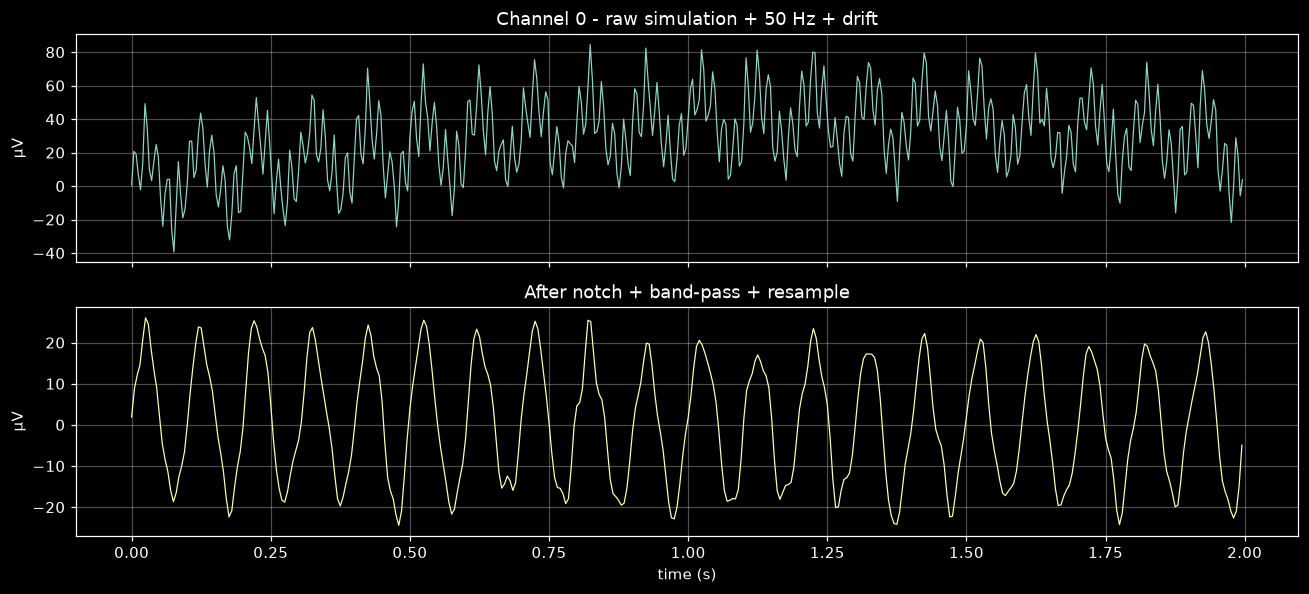

In [14]:
fs_clean = stages[3][2]
clean = stages[3][1]
n_raw = int(2 * MONTAGE.sfreq)
n_clean = int(2 * fs_clean)

fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
axes[0].plot(np.arange(n_raw) / MONTAGE.sfreq, stages[0][1][0, :n_raw], lw=0.8)
axes[0].set_ylabel("µV")
axes[0].set_title("Channel 0 - raw simulation + 50 Hz + drift")
axes[0].grid(alpha=0.3)

axes[1].plot(np.arange(n_clean) / fs_clean, clean[0, :n_clean], lw=0.8, color="C1")
axes[1].set_ylabel("µV")
axes[1].set_xlabel("time (s)")
axes[1].set_title("After notch + band-pass + resample")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Spectrum after every stage

Mean Welch PSD across channels. Stages 0–3 are still in µV, so they can share
one axis. Note how the 50 Hz peak drops by roughly 37 dB after the notch, the
0.2 Hz drift is attenuated by roughly 40 dB after the band-pass, and the
spectrum moves to the 200 Hz grid after resampling.

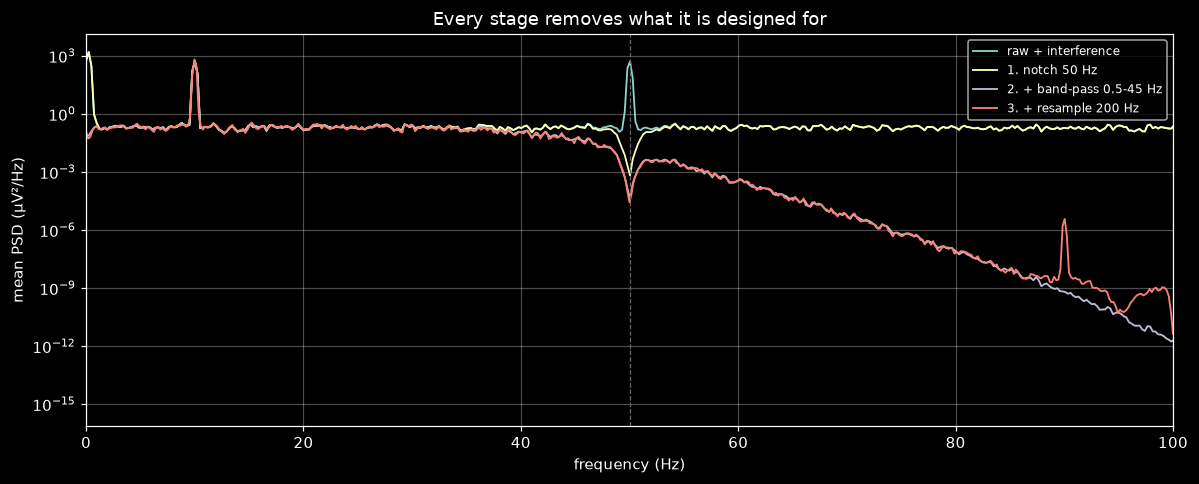

In [15]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for name, data, fs in stages[:4]:
    freqs, psd = welch(data, fs=fs, nperseg=min(1024, data.shape[1]), axis=-1)
    ax.semilogy(freqs, psd.mean(axis=0), label=name, lw=1.2)

ax.axvline(50.0, color="0.4", ls="--", lw=0.8)
ax.set_xlim(0, 100)
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("mean PSD (µV²/Hz)")
ax.set_title("Every stage removes what it is designed for")
ax.grid(alpha=0.3, which="both")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Quantitative check

In [16]:
def band_amplitude(data, freq, fs):
    n = data.shape[-1]
    k = int(round(freq * n / fs))
    return float((2 * np.abs(np.fft.rfft(data, axis=-1)[..., k]) / n).mean())


print(f"{'stage':28s} {'samples':>8s} {'Hz':>5s} {'50 Hz':>9s} {'10 Hz':>9s} {'0.2 Hz':>9s}")
for name, data, fs in stages[:4]:
    print(
        f"{name:28s} {data.shape[1]:8d} {fs:5g} "
        f"{band_amplitude(data, 50.0, fs):9.2f} "
        f"{band_amplitude(data, 10.0, fs):9.2f} "
        f"{band_amplitude(data, 0.2, fs):9.2f}"
    )

before = band_amplitude(stages[0][1], 50.0, MONTAGE.sfreq)
after = band_amplitude(stages[1][1], 50.0, MONTAGE.sfreq)
print(f"\n50 Hz notch attenuation: {20 * np.log10(before / after):.1f} dB")

drift_before = band_amplitude(stages[0][1], 0.2, MONTAGE.sfreq)
drift_after = band_amplitude(stages[2][1], 0.2, MONTAGE.sfreq)
print(f"0.2 Hz band-pass attenuation: {20 * np.log10(drift_before / drift_after):.1f} dB")

stage                         samples    Hz     50 Hz     10 Hz    0.2 Hz
raw + interference               2500   250     19.97     19.97     39.94
1. notch 50 Hz                   2500   250      0.28     19.97     39.94
2. + band-pass 0.5-45 Hz         2500   250      0.07     19.94      0.42
3. + resample 200 Hz             2000   200      0.07     19.96      0.42

50 Hz notch attenuation: 37.0 dB
0.2 Hz band-pass attenuation: 39.5 dB


## Final stage: z-score and clip

The output is dimensionless (standard deviations per channel, per window). The
histogram is shown on a log scale so the clipping at ±15 is visible; a z-score
window of 10 s rarely reaches it, but the limits protect downstream code from
artifacts.

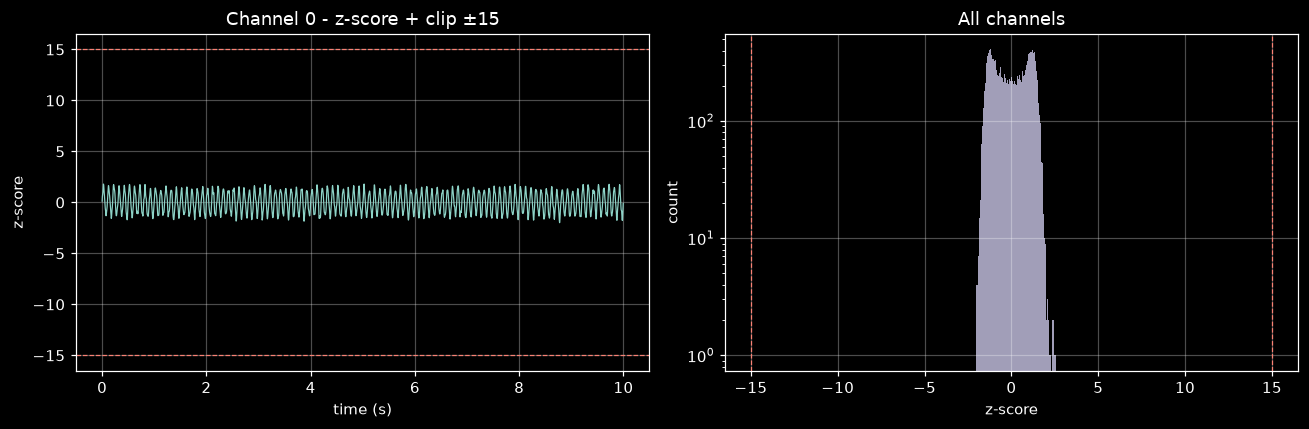

mean = 4.47e-10, std = 1.00
clipped samples = 0.00%
output = (8, 2000) at 200 Hz


In [17]:
final_data = stages[4][1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.plot(np.arange(final_data.shape[1]) / final.output_sfreq, final_data[0], lw=0.8)
for value in (-15, 15):
    ax.axhline(value, color="C3", ls="--", lw=0.8)
ax.set_xlabel("time (s)")
ax.set_ylabel("z-score")
ax.set_title("Channel 0 - z-score + clip ±15")
ax.grid(alpha=0.3)

ax = axes[1]
ax.hist(final_data.ravel(), bins=80, color="C2", alpha=0.85)
for value in (-15, 15):
    ax.axvline(value, color="C3", ls="--", lw=0.8)
ax.set_yscale("log")
ax.set_xlabel("z-score")
ax.set_ylabel("count")
ax.set_title("All channels")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"mean = {final_data.mean():.2e}, std = {final_data.std():.2f}")
print(f"clipped samples = {(np.abs(final_data) >= 15).mean() * 100:.2f}%")
print(f"output = {final_data.shape} at {final.output_sfreq:g} Hz")

## Live windows from the streamer

`WindowedPreprocessor` is a normal processor, so the exact same pipeline also
runs inside the ongoing stream. These are the windows it produced while the
notebook was running: one result per completed 10 s window, each already at
200 Hz and covering the whole window.

live windows captured: 2
  0: shape=(8, 2000)  t=10.00 s  dtype=float32
  1: shape=(8, 2000)  t=20.00 s  dtype=float32


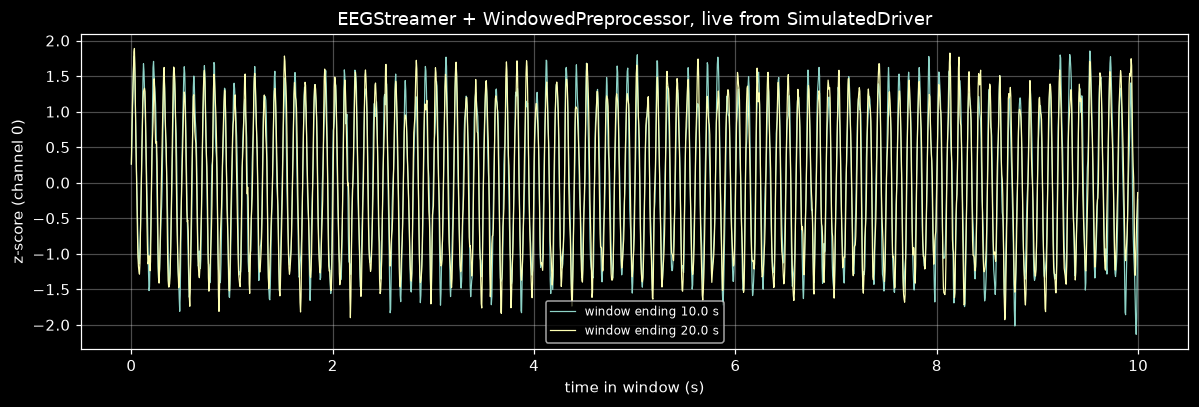

In [18]:
print(f"live windows captured: {len(processed)}")
for index, (clean, t_end) in enumerate(processed):
    print(f"  {index}: shape={clean.shape}  t={t_end:.2f} s  dtype={clean.dtype}")

if processed:
    fig, ax = plt.subplots(figsize=(11, 3.8))
    for index, (clean, t_end) in enumerate(processed):
        time_axis = np.arange(clean.shape[1]) / preprocessor.output_sfreq
        ax.plot(time_axis, clean[0], lw=0.8, label=f"window ending {t_end:.1f} s")
    ax.set_xlabel("time in window (s)")
    ax.set_ylabel("z-score (channel 0)")
    ax.set_title("EEGStreamer + WindowedPreprocessor, live from SimulatedDriver")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## Takeaways

- The preprocessing package only adds the signal transformation. The driver,
  the streamer, the ring buffer, the LSL outlet and the montage are the existing
  `brainaccess_connection` objects.
- `WindowedPreprocessor` is a regular processor: `streamer.add_processor(...)`
  is the only integration point. Pass `window_s=streamer.window_s` so it
  preprocesses the **whole established window**, once per completed window.
- The order matters: the notch runs before resampling so the 50 Hz interference
  cannot alias into the 200 Hz band.
- The z-score removes absolute amplitude. If a downstream step needs µV (RMS,
  band power), compute it **before** this stage or keep the pre-z-score signal.
- Filtering an isolated window has small edge transients. Use windows of at
  least 4 s (8–10 s is better for the 0.5 Hz high-pass), or stateful filters for
  a continuous stream.
- `WindowedPreprocessor` reports `skipped_windows` and `shifted_windows`.
  Choose a chunk size that divides `window_s * sfreq` (40 ms at 250 Hz is 10
  samples, so 10 s divides exactly) to keep every window aligned and
  non-overlapping.